# Final Report — Breast Cancer Wisconsin (Diagnostic): A Biological Story

**Course:** UE 5BM753 — Supervised and Unsupervised Learning for Biology
**Deliverable:** Final report (Python component)

**Status: SKELETON.** This notebook lays out the structure agreed on by the group. Sections
marked **`[TODO — <owner>]`** are intentionally left empty for that person to fill in.
Sections without a `[TODO]` tag are already backed by real, executed results (mostly
reused from `01_Milestone1.ipynb`, which screened the baseline methods) and can be
extended but should not need to be redone from scratch.


## Setup

Run this cell once, before any other cell below. It defines the paths used throughout the
notebook, fixes the random seed, and imports the reusable functions kept in
`01_scripts/` (shared with `01_Milestone1.ipynb`) so nothing here needs to be redefined.


In [6]:
import os
import sys
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append(os.path.join("..", "01_scripts"))
from dataset import load_data, get_feature_columns
from plots import plot_class_balance, plot_pca_projection  # shared plotting functions -- see 01_scripts/plots.py
# shared evaluation functions -- see 01_scripts/evaluation.py (evaluate_classifier,
# cross_validate_classifiers, run_kmeans_range); import the ones you need in each zoom.


# ---------------------------
# Main paths
# ---------------------------
DATA_PATH = os.path.join("..", "02_data", "raw", "10_Breast_Cancer_Wisconsin_Diagnostic.csv")
RESULTS_DIR = os.path.join("..", "04_results")
FIGURES_DIR = os.path.join("..", "05_figures")
TABLES_DIR = os.path.join(RESULTS_DIR, "tables")
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(TABLES_DIR, exist_ok=True)

# ---------------------------
# Run mode
# ---------------------------
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# ---------------------------
# Cosmetic choices
# ---------------------------
sns.set_theme(style="whitegrid", font_scale=1.0)
plt.rcParams["figure.dpi"] = 110


print("Libraries loaded. Random seed fixed at", RANDOM_STATE)


Libraries loaded. Random seed fixed at 42


## 1. Context & Gap

### 1.1 Clinical context



### 1.2 Gap



## 2. Question

- **Q1 (supervised):** Can we reliably predict the diagnosis (benign/malignant) from the
  30 morphological features? Which standard classifier performs best as a baseline?
- **Q2 (unsupervised):** Do the data naturally separate into two clusters that match the
  known diagnosis, without ever using the labels?
- **Q3 (feature relevance):** Which features are the most redundant, and which carry the
  most discriminative signal?




## 3. Data

Breast Cancer Wisconsin (Diagnostic): 569 samples, 30 continuous morphological features
(Section 1).


### 3.1 Variables

For each sample, 10 base morphological properties of cell nuclei are measured: radius,
texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry,
and fractal dimension. Each property is summarized by three statistics computed over all
nuclei in the image — mean, standard error (SE), and worst (average of the three largest
values) — giving the 30 continuous features used throughout this report (e.g.
`radius_mean`, `radius_se`, `radius_worst`). Full column-by-column descriptions are in
`02_data/data_dictionary.md`.


### 3.2 Quality checks

Three checks before any modeling: missing values, duplicated rows, and outliers
(1.5×IQR rule per feature). Outliers are flagged for reporting only, not removed — in a
biological dataset an "outlier" cell may simply reflect a more aggressive tumor
phenotype, a judgment call that needs domain knowledge, not an automatic cutoff.


In [7]:
from dataset import check_missing_values, check_duplicates, detect_outliers_iqr

df = load_data(DATA_PATH)
features = get_feature_columns(df)

n_missing = check_missing_values(df).sum()
n_duplicates = check_duplicates(df)
outlier_report = detect_outliers_iqr(df, features)
outlier_report.to_csv(os.path.join(TABLES_DIR, "00_outlier_report.csv"), index=False)

print(f"Missing values (total): {n_missing}")
print(f"Duplicated rows: {n_duplicates}\n")
print("Top 8 features by outlier count (1.5*IQR rule):")
display(outlier_report.head(8))


Missing values (total): 0
Duplicated rows: 0

Top 8 features by outlier count (1.5*IQR rule):


,feature,n_outliers,pct_outliers
13,area_se,65,11.42
10,radius_se,38,6.68
12,perimeter_se,38,6.68
23,area_worst,35,6.15
14,smoothness_se,30,5.27
19,fractal_dimension_se,28,4.92
15,compactness_se,28,4.92
18,symmetry_se,27,4.75


**Reading.**
- No missing values and no duplicated rows: no imputation or de-duplication is needed before modeling. 

- The features with the most flagged outliers are the standard-error (`_se`) variables and `area_worst` — these describe within-image variability and the size of the largest nuclei, both biologically expected to have a heavier-tailed distribution in more aggressive tumors, which is why they are flagged for reporting here rather than removed.


## 4. Approach (Methods)

### 4.1 Exploratory Data Analysis

Data loading and quality checks are already done in Section 3. Four complementary views
are established here, each feeding directly into a later question.

- **Class balance** — motivates using F2/ROC-AUC rather than accuracy alone as the
  deciding metrics from Section 4.2 onward.
- **Correlation heatmap** — shows which of the 30 raw features are redundant (Q3),
  motivating Section 4.3's feature selection.
- **Boxplots by diagnosis** — shows which features visually separate benign from
  malignant (Q3), i.e. carry discriminative signal worth keeping.
- **PCA projection & variance explained** — a quick visual check of class separability
  in reduced space; the 2D coordinates are reused as the backdrop for the Spectral
  Clustering figure in Section 4.5.


**Class balance.** The split below (~63% benign / ~37% malignant) is moderately
imbalanced.


Dataset shape: 569 samples x 30 features


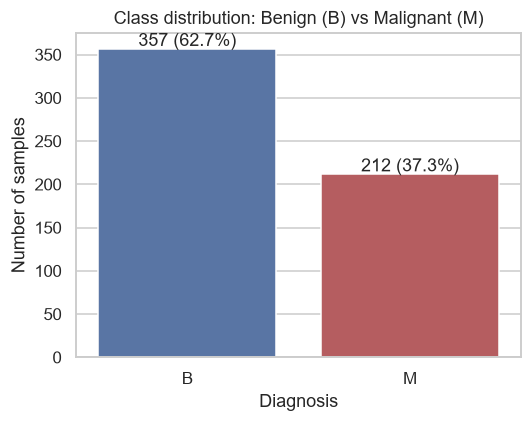

In [8]:
from plots import plot_class_balance

print(f"Dataset shape: {df.shape[0]} samples x {len(features)} features")
plot_class_balance(df, os.path.join(FIGURES_DIR, "final_01_class_balance.png"))

**Correlation heatmap.** Feature pairs with |r| > 0.95 are highly redundant — carrying
near-identical information — which motivates Section 4.3's feature selection: several of
the 30 raw features can likely be dropped without losing signal.


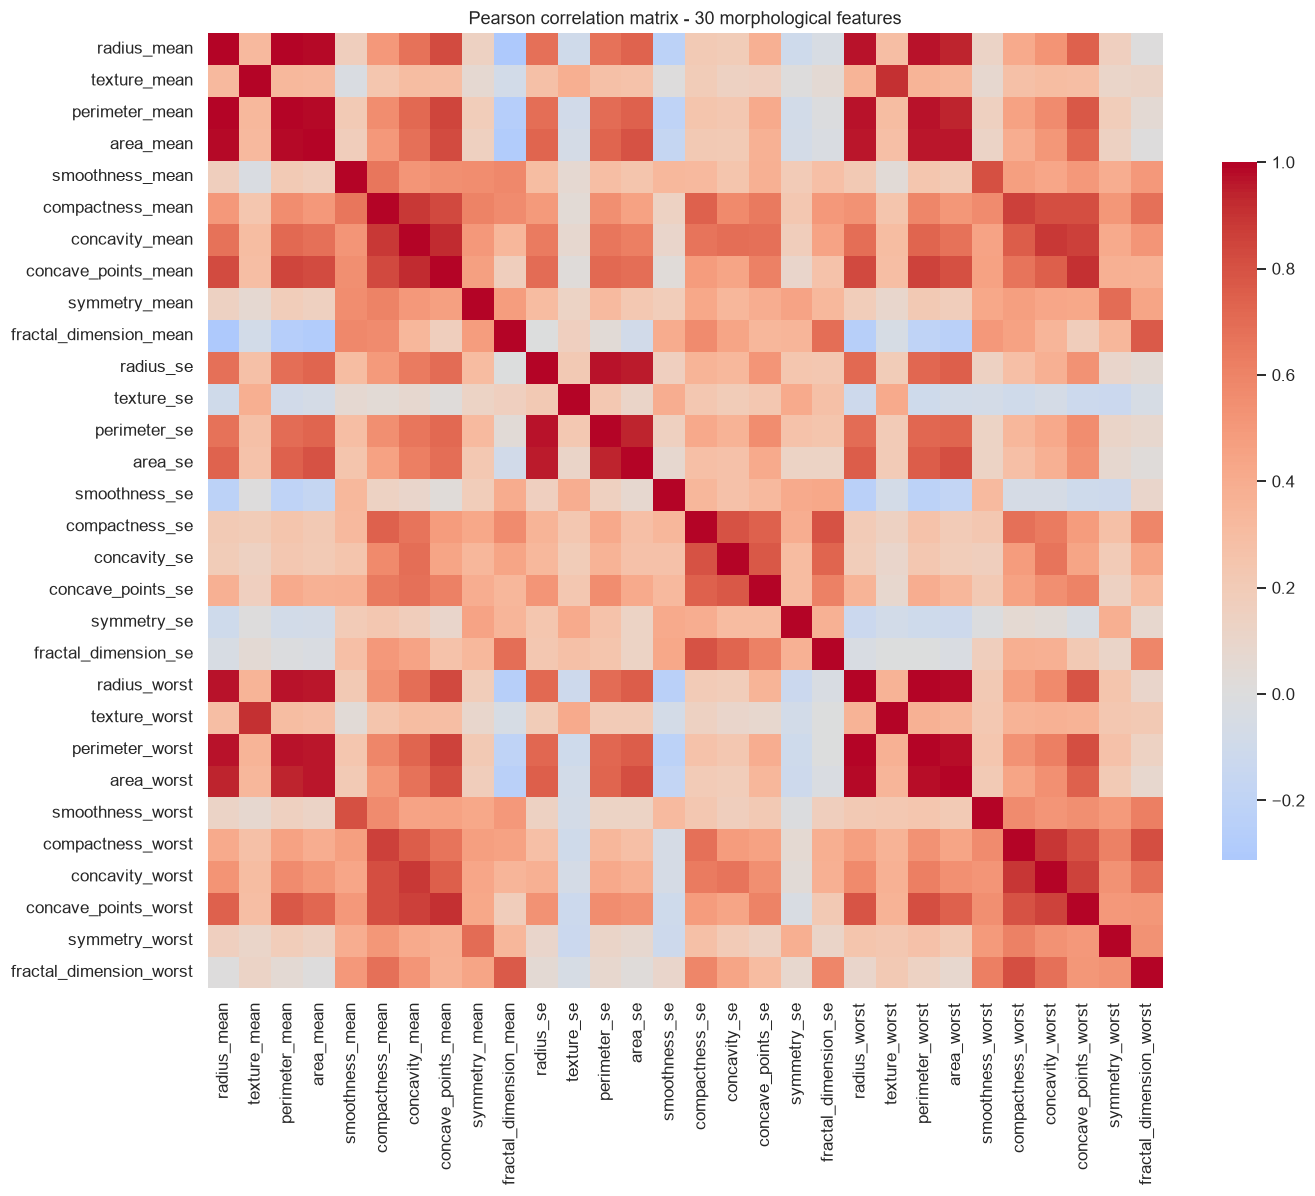

Feature pairs with |correlation| > 0.95 (15 pairs found):

  radius_mean                  <-> perimeter_mean                r = 0.998
  radius_worst                 <-> perimeter_worst               r = 0.994
  radius_mean                  <-> area_mean                     r = 0.987
  perimeter_mean               <-> area_mean                     r = 0.987
  radius_worst                 <-> area_worst                    r = 0.984
  perimeter_worst              <-> area_worst                    r = 0.978
  radius_se                    <-> perimeter_se                  r = 0.973
  perimeter_mean               <-> perimeter_worst               r = 0.970
  radius_mean                  <-> radius_worst                  r = 0.970
  perimeter_mean               <-> radius_worst                  r = 0.969


In [9]:
from plots import plot_correlation_heatmap, get_top_correlated_pairs

plot_correlation_heatmap(df, features, os.path.join(FIGURES_DIR, "final_02_correlation_heatmap.png"))

top_pairs = get_top_correlated_pairs(df, features, threshold=0.95)
pd.DataFrame(top_pairs, columns=["feature_1", "feature_2", "pearson_r"]).to_csv(
    os.path.join(TABLES_DIR, "01_correlated_feature_pairs.csv"), index=False)

print(f"Feature pairs with |correlation| > 0.95 ({len(top_pairs)} pairs found):\n")
for f1, f2, corr_val in top_pairs[:10]:
    print(f"  {f1:28s} <-> {f2:28s}  r = {corr_val:.3f}")


**Boxplots by diagnosis (mean features).** Features whose distributions clearly separate
benign from malignant visually carry discriminative signal — the more separated the two
boxes, the more useful that feature is likely to be for Section 4.3's feature selection
and the Section 4.4 zoom.


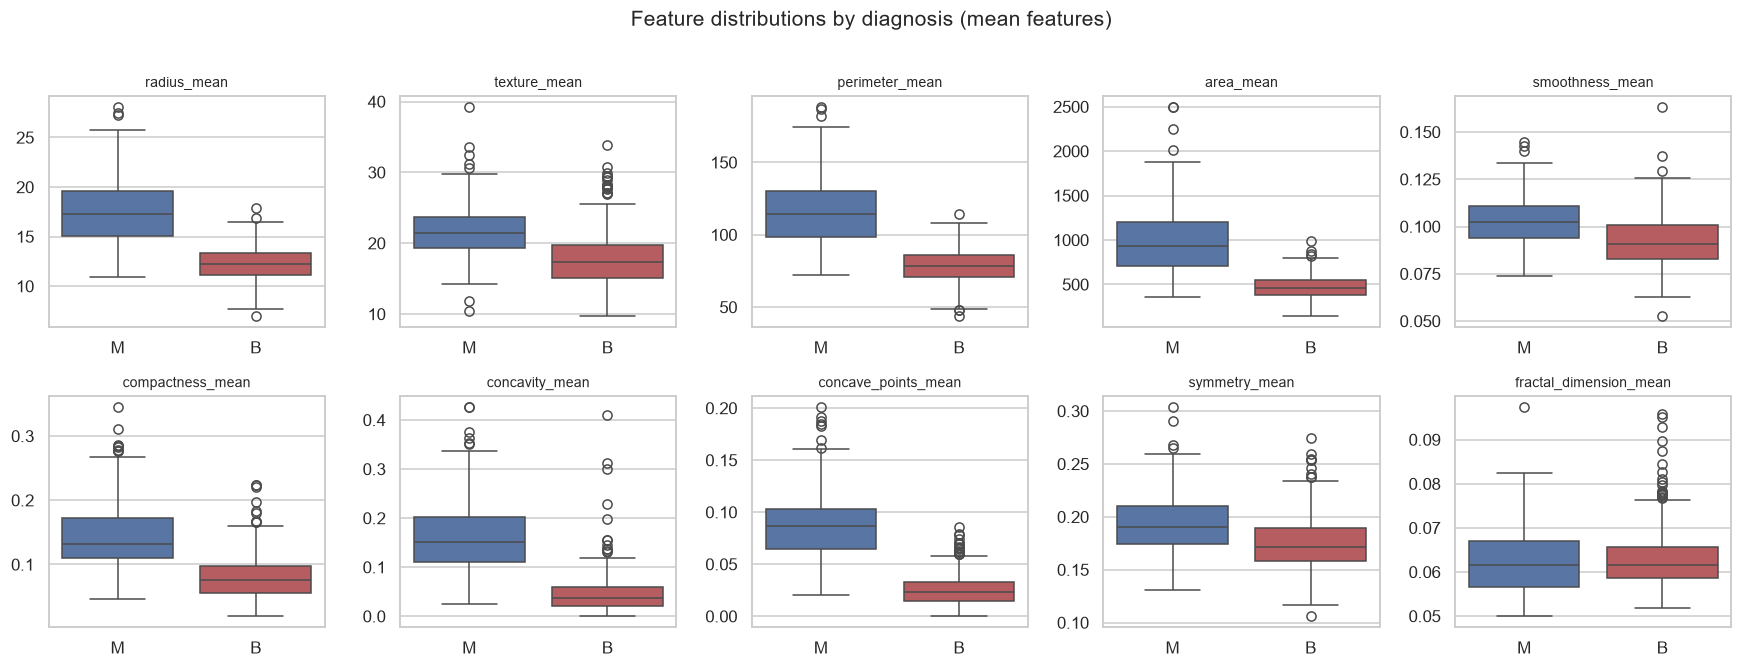

In [10]:
from plots import plot_boxplots_by_diagnosis

mean_features = [f for f in features if f.endswith("_mean")]
plot_boxplots_by_diagnosis(df, mean_features, os.path.join(FIGURES_DIR, "final_03_boxplots_mean_features.png"))


**PCA projection & variance explained.** Standardizing then projecting onto the first 2
principal components gives a quick visual check of class separability, and produces the
2D coordinates reused to visualize Spectral Clustering's output later (Section 4.5). The
scree plot shows how much of the total variance those first components actually capture.


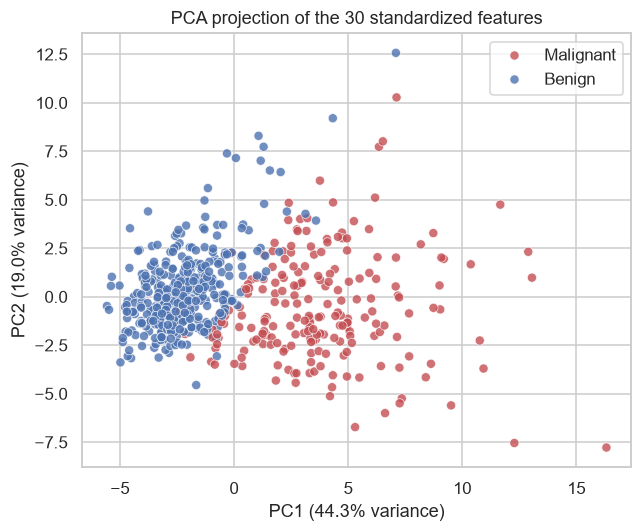

PC1 + PC2 explain 63.2% of total variance


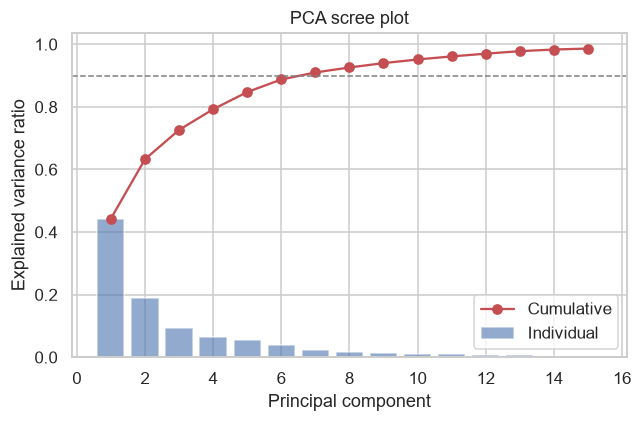

7 principal components are needed to reach 90% cumulative variance


In [11]:
from sklearn.preprocessing import StandardScaler
from plots import plot_pca_scree

X_scaled_full = StandardScaler().fit_transform(df[features].values)
pca_full, X_pca_full = plot_pca_projection(
    X_scaled_full, df["label"].values,
    os.path.join(FIGURES_DIR, "final_04_pca_projection.png"),
    random_state=RANDOM_STATE,
)
print(f"PC1 + PC2 explain {sum(pca_full.explained_variance_ratio_)*100:.1f}% of total variance\n")

cum_var = plot_pca_scree(X_scaled_full, os.path.join(FIGURES_DIR, "final_05_pca_scree.png"))
n_90 = int((cum_var < 0.90).sum() + 1)
print(f"{n_90} principal components are needed to reach 90% cumulative variance")


### 4.2 Initial screening

10 supervised classifiers (Logistic Regression, KNN, SVM x3 kernels, LDA, QDA, Decision
Tree, Random Forest, AdaBoost) are compared with 10-fold stratified cross-validation, and
6 clustering methods (K-Means, Agglomerative x3 linkages, Spectral, DBSCAN) are evaluated
against the true diagnosis with external metrics (ARI, homogeneity, completeness,
V-measure, silhouette). The same screening was also run in Orange3 as a cross-check.
Model/hyperparameter choices are justified in `01_scripts/supervised_models.py` and
`01_scripts/unsupervised_models.py`. Run directly below (not just cited from
`01_Milestone1.ipynb`, which is a working draft and not part of this deliverable) so the
results are reproducible from this notebook alone.


In [12]:
from preprocessing import split_and_scale
from supervised_models import get_baseline_classifiers
from unsupervised_models import get_baseline_clusterers
from evaluation import cross_validate_classifiers, evaluate_clusterers

# "_all" suffix: full 30-feature split, used only for this screening stage. The
# zoom sections (4.4/4.5) re-split restricted to the selected features from 4.3 --
# don't reuse these variables there.
X_train_all, X_test_all, y_train, y_test, scaler_all = split_and_scale(
    df, features, test_size=0.3, random_state=RANDOM_STATE
)

classifiers = get_baseline_classifiers(random_state=RANDOM_STATE)
supervised_cv = cross_validate_classifiers(
    classifiers, X_train_all, y_train, cv_folds=10, random_state=RANDOM_STATE
)
supervised_cv.round(4).to_csv(os.path.join(TABLES_DIR, "02_supervised_cv_results.csv"), index=False)

clusterers = get_baseline_clusterers(random_state=RANDOM_STATE)
clustering_eval = evaluate_clusterers(clusterers, X_scaled_full, df["label"].values)
clustering_eval.round(4).to_csv(os.path.join(TABLES_DIR, "04_clustering_eval.csv"), index=False)

print(f"Train set: {X_train_all.shape[0]} samples, test set: {X_test_all.shape[0]} samples\n")
print("Supervised screening (10-fold CV on train set):")
display(supervised_cv[["model", "accuracy_mean", "recall_mean", "f1_mean", "f2_mean", "roc_auc_mean"]].round(4))
print("\nClustering screening (all 569 samples, scaled):")
display(clustering_eval.round(4))


Train set: 398 samples, test set: 171 samples

Supervised screening (10-fold CV on train set):


,model,accuracy_mean,recall_mean,f1_mean,f2_mean,roc_auc_mean
9,AdaBoost,0.9674,0.9324,0.9543,0.9406,0.9943
4,SVM (poly),0.8946,0.7167,0.8284,0.7567,0.9930
3,SVM (RBF),0.9749,0.9529,0.9655,0.9577,0.9927
0,Logistic Regression,0.9773,0.9524,0.9684,0.9586,0.9926
7,LDA,0.9523,0.8786,0.9297,0.8979,0.9922
2,SVM (linear),0.9598,0.9257,0.9434,0.9323,0.9918
8,QDA,0.9697,0.9386,0.9573,0.9457,0.9885
6,Random Forest,0.9473,0.9257,0.9286,0.9262,0.9845
1,K-Nearest Neighbors,0.9573,0.8986,0.9387,0.9140,0.9841
5,Decision Tree,0.9146,0.8981,0.8850,0.8918,0.9110



Clustering screening (all 569 samples, scaled):


,model,n_clusters_found,silhouette,homogeneity,completeness,v_measure,ARI_vs_diagnosis
0,K-Means,2,0.3434,0.5249,0.5401,0.5324,0.6536
1,Agglomerative (ward),2,0.3394,0.4462,0.4681,0.4569,0.5750
2,Agglomerative (average),2,0.6340,0.0079,0.1589,0.0151,0.0073
3,Agglomerative (complete),2,0.6607,0.0053,0.1489,0.0102,0.0048
4,Spectral,2,0.3367,0.6497,0.6762,0.6627,0.7608
5,DBSCAN,2,0.0307,0.2584,0.2117,0.2327,0.2649


### 4.3 Feature Selection
 
To address the severe collinearity identified in 4.1 (Pearson $|r| > 0.95$), a strict feature selection pipeline was implemented. Its objective is to reduce the dimensionality from 30 continuous variables down to a restricted, highly discriminative subset without sacrificing diagnostic sensitivity.
 
**Methodology and Cross-Validation Protocol**
To prevent any data leakage, the entire selection process is strictly confined to the training set (`X_train`, `X_train_scaled`). Two families of methods are compared:
1. **Filter Methods**: Variance Threshold and ANOVA F-value test (`SelectFdr`, $\alpha = 0.05$).
2. **Embedded Methods**: L1-penalized Logistic Regression, L1-penalized LinearSVC, and Elastic-Net.
 
Each isolated subset is evaluated by training a benchmark Logistic Regression model. Performance is quantified by the **mean Recall via 5-fold cross-validation** (Recall is prioritized to minimize False Negatives, the most critical error in oncological diagnostics).
 
**Justification for a Shared Feature Subset**
The subset isolated here will be reused identically for both the Supervised Zoom (4.4) and the Unsupervised Zoom (4.5) to preserve the comparative integrity of the report. Constraining the clustering algorithm to use only the features deemed critical by the supervised model allows us to address biological question Q2 (do these malignant morphological markers naturally form distinct clinical clusters without relying on labels?).
 
The code below: (1) eliminates collinear features, (2) compares 5 selection methods using 5-fold CV Recall, (3) fine-tunes the regularization parameter `C` of the chosen method (L1 Logistic Regression) to identify the performance plateau, and (4) exports the final restricted datasets along with their evaluation.

Variables supprimées pour colinéarité (>0.95) : 7
  -> ['perimeter_mean', 'area_mean', 'perimeter_se', 'area_se', 'radius_worst', 'perimeter_worst', 'area_worst'] 

Variables restantes avant sélection : 23

  -> ['radius_mean', 'texture_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave_points_se', 'symmetry_se', 'fractal_dimension_se', 'texture_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave_points_worst', 'symmetry_worst', 'fractal_dimension_worst'] 

--- Comparatif des méthodes de sélection (Recall, CV 5-fold) ---
                         Méthode  Nb features  Recall CV (moy.)  Recall CV (std)
               LogReg L1 (C=0.1)            7            0.9389           0.0405
           LinearSVC L1 (C=0.05)            9            0.9389           0.0456
      Elastic-Net (l1_ratio=0.7)       

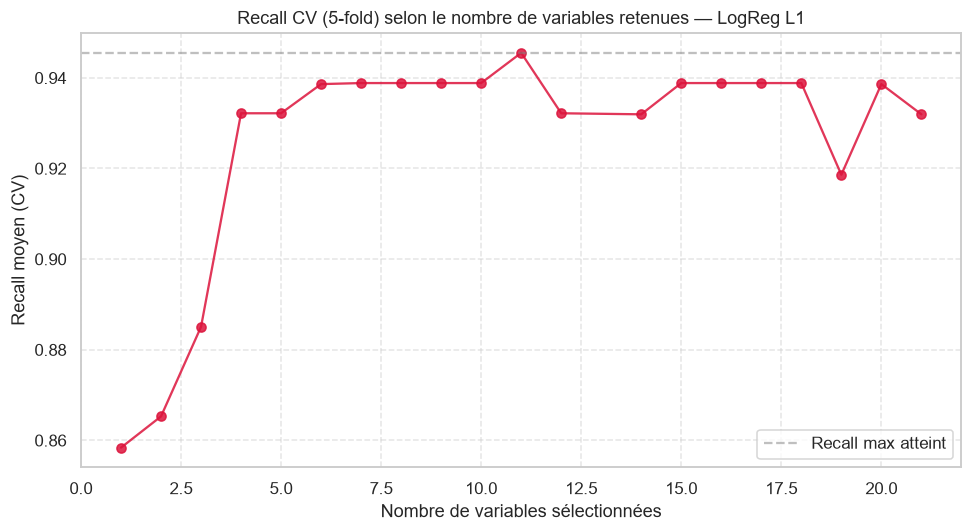

C retenu (LogReg L1)                : 0.0408
Nombre de variables retenues (plateau) : 6
Recall CV associé                    : 0.9386
Variables sélectionnées              : ['radius_mean', 'concave_points_mean', 'radius_se', 'texture_worst', 'concave_points_worst', 'symmetry_worst']

--- Évaluation du sous-ensemble final retenu (jeu de test) ---
                                 Accuracy  Precision  Recall  F1-score  F2-score  ROC-AUC
LogReg (baseline, features 4.3)    0.9766     0.9839  0.9531    0.9683    0.9591   0.9956


In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_selection import VarianceThreshold, SelectFdr, f_classif, SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.model_selection import cross_val_score
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, fbeta_score, roc_auc_score
)

RANDOM_STATE = 42

# ------------------------------------------------------------------
# 1) Suppression des variables colinéaires (|r| > 0.95)
# ------------------------------------------------------------------
df_train_scaled = pd.DataFrame(X_train_all, columns=features)
corr_matrix = df_train_scaled.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
collinear_features = [col for col in upper.columns if any(upper[col] > 0.95)]

features_clean = [f for f in features if f not in collinear_features]
X_train_clean = df_train_scaled[features_clean].values
X_test_clean = pd.DataFrame(X_test_all, columns=features)[features_clean].values

print(f"Variables supprimées pour colinéarité (>0.95) : {len(collinear_features)}")
print(f"  -> {collinear_features} \n")
print(f"Variables restantes avant sélection : {len(features_clean)}\n")
print(f"  -> {features_clean} \n")

# ------------------------------------------------------------------
# 2) Benchmark des méthodes de sélection (filtre + embarquées)
# ------------------------------------------------------------------
selectors = {
    "Variance Threshold (0.01)": VarianceThreshold(threshold=0.01).fit(X_train_clean),
    "ANOVA F / SelectFdr (alpha=0.05)": SelectFdr(f_classif, alpha=0.05).fit(X_train_clean, y_train),
    "LogReg L1 (C=0.1)": SelectFromModel(
        LogisticRegression(penalty='l1', solver='liblinear', C=0.1, random_state=RANDOM_STATE)
    ).fit(X_train_clean, y_train),
    "LinearSVC L1 (C=0.05)": SelectFromModel(
        LinearSVC(penalty='l1', dual=False, C=0.05, random_state=RANDOM_STATE)
    ).fit(X_train_clean, y_train),
    "Elastic-Net (l1_ratio=0.7)": SelectFromModel(
        LogisticRegression(penalty='elasticnet', solver='saga', l1_ratio=0.7,
                           C=0.1, max_iter=5000, random_state=RANDOM_STATE)
    ).fit(X_train_clean, y_train),
}

benchmark_rows = []
for name, selector in selectors.items():
    mask = selector.get_support()
    sub_features = np.array(features_clean)[mask].tolist()
    X_sub = X_train_clean[:, mask]

    cv_recall = cross_val_score(
        LogisticRegression(random_state=RANDOM_STATE), X_sub, y_train, cv=5, scoring='recall'
    )
    benchmark_rows.append({
        "Méthode": name,
        "Nb features": int(mask.sum()),
        "Recall CV (moy.)": cv_recall.mean(),
        "Recall CV (std)": cv_recall.std(),
        "Variables": sub_features,
    })

df_benchmark = pd.DataFrame(benchmark_rows).sort_values("Recall CV (moy.)", ascending=False)
print("--- Comparatif des méthodes de sélection (Recall, CV 5-fold) ---")
print(df_benchmark[["Méthode", "Nb features", "Recall CV (moy.)", "Recall CV (std)"]]
      .to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print()
for row in benchmark_rows:
    print(f"--- {row['Méthode']} ({row['Nb features']} variables) ---")
    print(", ".join(row["Variables"]) + "\n")

# ------------------------------------------------------------------
# 3) Fine-tuning de C pour LogReg L1 (méthode retenue) : recherche du plateau
# ------------------------------------------------------------------
C_values = np.logspace(-3, 2, 60)
plateau_results = {}  # nb_features -> (meilleur recall CV, C associé, mask)

for C_val in C_values:
    sel = SelectFromModel(
        LogisticRegression(penalty='l1', solver='liblinear', C=C_val, random_state=RANDOM_STATE)
    ).fit(X_train_clean, y_train)
    mask = sel.get_support()
    n_feat = int(mask.sum())
    if n_feat == 0:
        continue
    X_sub = X_train_clean[:, mask]
    cv_recall = cross_val_score(
        LogisticRegression(random_state=RANDOM_STATE), X_sub, y_train, cv=5, scoring='recall'
    ).mean()
    if n_feat not in plateau_results or cv_recall > plateau_results[n_feat][0]:
        plateau_results[n_feat] = (cv_recall, C_val, mask)

sorted_n = sorted(plateau_results.keys())
sorted_recall = [plateau_results[n][0] for n in sorted_n]

plt.figure(figsize=(9, 5))
plt.plot(sorted_n, sorted_recall, marker='o', color='crimson', alpha=0.85)
plt.axhline(max(sorted_recall), linestyle='--', color='grey', alpha=0.5, label="Recall max atteint")
plt.title("Recall CV (5-fold) selon le nombre de variables retenues — LogReg L1")
plt.xlabel("Nombre de variables sélectionnées")
plt.ylabel("Recall moyen (CV)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# On retient le plus petit sous-ensemble atteignant >= 99% du recall max (le "plateau")
recall_max = max(sorted_recall)
n_selected = min(n for n in sorted_n if plateau_results[n][0] >= 0.99 * recall_max)
best_recall, best_C, best_mask = plateau_results[n_selected]

selected_features = np.array(features_clean)[best_mask].tolist()

print(f"C retenu (LogReg L1)                : {best_C:.4f}")
print(f"Nombre de variables retenues (plateau) : {n_selected}")
print(f"Recall CV associé                    : {best_recall:.4f}")
print(f"Variables sélectionnées              : {selected_features}\n")

# ------------------------------------------------------------------
# 4) Export des jeux de données restreints finaux (réutilisés en 4.4 et 4.5)
# ------------------------------------------------------------------
X_train_sel = X_train_clean[:, best_mask]
X_test_sel = X_test_clean[:, best_mask]

# ------------------------------------------------------------------
# 5) Évaluation du modèle de référence sur le sous-ensemble final
# ------------------------------------------------------------------
model_ref = LogisticRegression(random_state=RANDOM_STATE)
model_ref.fit(X_train_sel, y_train)
y_pred = model_ref.predict(X_test_sel)
y_prob = model_ref.predict_proba(X_test_sel)[:, 1]

metrics_final = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1-score": f1_score(y_test, y_pred),
    "F2-score": fbeta_score(y_test, y_pred, beta=2),
    "ROC-AUC": roc_auc_score(y_test, y_prob),
}

df_metrics_final = pd.DataFrame([metrics_final], index=["LogReg (baseline, features 4.3)"])
print("--- Évaluation du sous-ensemble final retenu (jeu de test) ---")
print(df_metrics_final.to_string(float_format=lambda x: f"{x:.4f}"))

### 4.4 Zoom — Logistic Regression
 
**Hyperparameter Tuning**
Using the feature subset selected in 4.3 (`X_train_sel`, `X_test_sel` — these are the fixed features; `X_train_all`/`X_test_all` are no longer used here), a 5-fold cross-validation grid search is performed to find the optimal regularization strength `C` for the **final** Logistic Regression model, over a logarithmic grid $C \in [10^{-3}, 10^{2}]$. The optimized score remains **Recall**, which aligns with the priority given to minimizing False Negatives in 4.3. This `C` is distinct from the one used in 4.3: it no longer determines which features to keep, but how to tune the final model on these pre-fixed features.
 
**Selected Configuration**
The optimal `C` obtained from `GridSearchCV` is retained, and the final model is retrained on the entire restricted training set.
 
**Evaluation**
The final model is evaluated on the held-out test set using the same metrics as Milestone 1: accuracy, precision, recall, F1, F2, and ROC-AUC — via `evaluate_classifier` (`01_scripts/evaluation.py`). ROC curves and confusion matrices are generated via `plot_roc_curves` and `plot_confusion_matrices` (`01_scripts/plots.py`), which accept a dictionary formatted as `{name: model}` — used here with a single tuned model. These results feed directly into Section 5.3.

Meilleur paramètre C (modèle final) : 0.2593
Recall CV associé                   : 0.9386


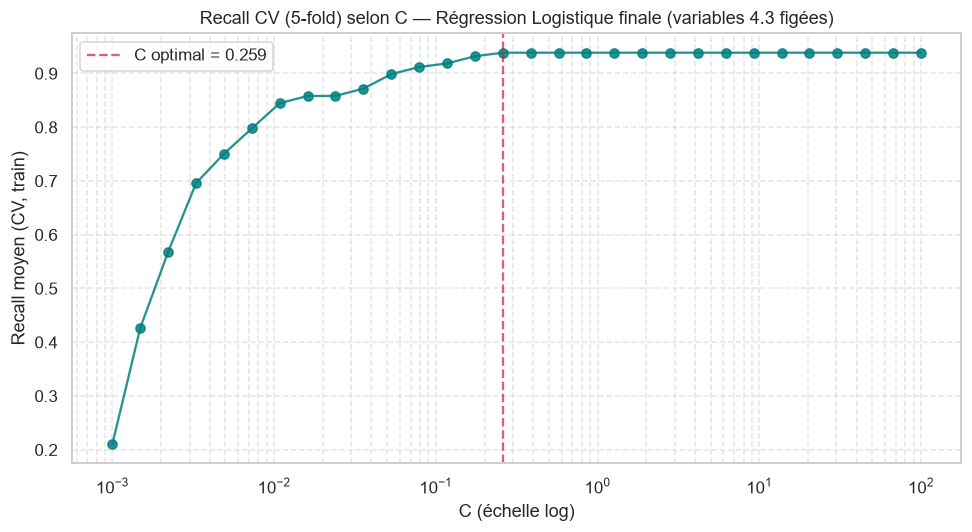

--- Évaluation finale (jeu de test) ---


,accuracy,precision,recall,f1,f2,roc_auc
Régression Logistique (features 4.3),0.9825,1.0,0.9531,0.976,0.9621,0.9959


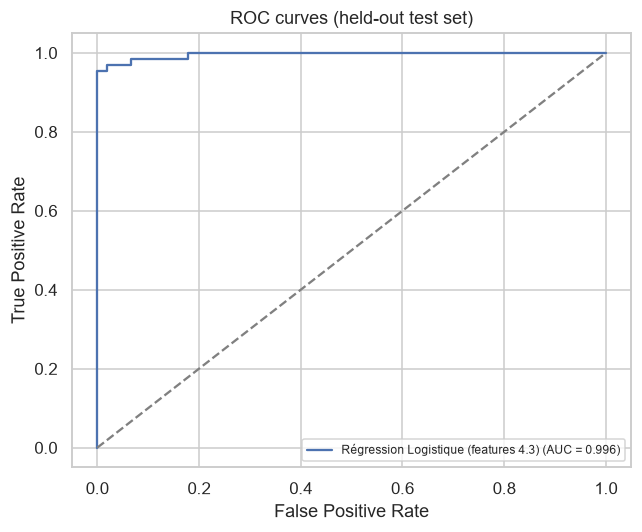

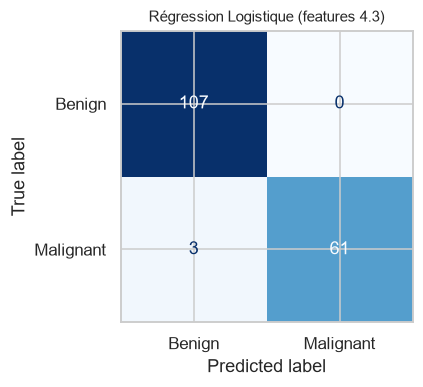

In [17]:
from sklearn.model_selection import GridSearchCV
from evaluation import evaluate_classifier
from plots import plot_roc_curves, plot_confusion_matrices
 
MODEL_NAME = "Régression Logistique (features 4.3)"
 
# ------------------------------------------------------------------
# 1) Recherche d'hyperparamètre (C) par validation croisée 
# ------------------------------------------------------------------
param_grid = {"C": np.logspace(-3, 2, 30)}
 
grid_logreg = GridSearchCV(
    LogisticRegression(random_state=RANDOM_STATE, max_iter=5000),
    param_grid,
    cv=5,
    scoring='recall',
    n_jobs=-1
)
grid_logreg.fit(X_train_sel, y_train)
 
print(f"Meilleur paramètre C (modèle final) : {grid_logreg.best_params_['C']:.4f}")
print(f"Recall CV associé                   : {grid_logreg.best_score_:.4f}\n")
 
results_cv = pd.DataFrame(grid_logreg.cv_results_)
plt.figure(figsize=(9, 5))
plt.plot(results_cv["param_C"].astype(float), results_cv["mean_test_score"],
          marker='o', color='teal', alpha=0.85)
plt.axvline(grid_logreg.best_params_['C'], linestyle='--', color='crimson', alpha=0.7,
            label=f"C optimal = {grid_logreg.best_params_['C']:.3f}")
plt.xscale('log')
plt.title("Recall CV (5-fold) selon C — Régression Logistique finale (variables 4.3 figées)")
plt.xlabel("C (échelle log)")
plt.ylabel("Recall moyen (CV, train)")
plt.legend()
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "final_07_logreg_c_tuning.png"))
plt.show()
 
# ------------------------------------------------------------------
# 2) Modèle final et évaluation sur le jeu de test tenu à l'écart
# ------------------------------------------------------------------
best_logreg = grid_logreg.best_estimator_
models_dict = {MODEL_NAME: best_logreg}
 
# Appel de evaluate_classifier avec le modèle unique
metrics_logreg = evaluate_classifier(best_logreg, X_train_sel, y_train, X_test_sel, y_test)
 
df_results_logreg = pd.DataFrame([metrics_logreg], index=[MODEL_NAME])
df_results_logreg.to_csv(os.path.join(TABLES_DIR, "05_logreg_final_metrics.csv"))
 
print("--- Évaluation finale (jeu de test) ---")
display(df_results_logreg.round(4))
 
plot_roc_curves(
    classifiers=models_dict, 
    X_tr=X_train_sel, 
    y_tr=y_train, 
    X_te=X_test_sel, 
    y_te=y_test, 
    out_path=os.path.join(FIGURES_DIR, "final_09_logreg_roc_curve.png")
)
plot_confusion_matrices(
    classifiers=models_dict, 
    X_tr=X_train_sel, 
    y_tr=y_train, 
    X_te=X_test_sel, 
    y_te=y_test, 
    out_path=os.path.join(FIGURES_DIR, "final_08_logreg_confusion_matrix.png")
)

### 4.5 Zoom — Spectral Clustering

`[TODO — Ann-Solène: Spectral Clustering zoom]`

Expected content: Spectral Clustering re-run on the features selected in Section 4.3
(instead of all 30), with the affinity/`n_clusters` choices justified, and a plan for how
its output will be visualized and compared to the true diagnosis (e.g. PCA projection
colored by predicted cluster vs. true label, as in Milestone 1 Section 6).

**Reuse, don't redefine:** `from plots import plot_cluster_vs_diagnosis` — same function
Milestone 1 used for its Spectral highlight figure, see `01_scripts/plots.py`.

**Blocked by Section 4.3** (needs the selected feature subset first).


## 5. Results

### 5.1 Screening (condensed)

Only the two methods carried forward to the zooms below are highlighted; full results for
all 10 supervised models and 6 clustering methods are the tables saved by Section 4.2's
code above (`04_results/tables/02_supervised_cv_results.csv` and `04_clustering_eval.csv`).


In [14]:
supervised_cv = pd.read_csv(os.path.join(TABLES_DIR, "02_supervised_cv_results.csv"))
clustering_eval = pd.read_csv(os.path.join(TABLES_DIR, "04_clustering_eval.csv"))

# "Overall" best = lowest average rank across all 6 metrics at once (F2 added
# alongside F1: it weighs recall twice as heavily as precision, matching this
# project's clinical priority of not missing a malignant case), not just the
# single highest ROC-AUC -- no one metric should decide a "best" model.
_metrics = ["accuracy_mean", "precision_mean", "recall_mean", "f1_mean", "f2_mean", "roc_auc_mean"]
_avg_rank = supervised_cv.set_index("model")[_metrics].rank(ascending=False).mean(axis=1)
supervised_condensed = (
    supervised_cv.set_index("model")[_metrics]
    .assign(avg_rank_across_6_metrics=_avg_rank.round(2))
    .sort_values("avg_rank_across_6_metrics")
    .head(3)
    .reset_index()
)
clustering_condensed = (
    clustering_eval.sort_values("ARI_vs_diagnosis", ascending=False)
    .loc[:, ["model", "silhouette", "ARI_vs_diagnosis"]]
    .head(3)
    .reset_index(drop=True)
)

supervised_condensed.to_csv(os.path.join(TABLES_DIR, "final_00_screening_supervised_condensed.csv"), index=False)
clustering_condensed.to_csv(os.path.join(TABLES_DIR, "final_00_screening_clustering_condensed.csv"), index=False)

print("Top 3 supervised models by average rank across all 6 metrics (10-fold CV):")
display(supervised_condensed)
print("\nTop 3 clustering methods by ARI vs. true diagnosis:")
display(clustering_condensed)


Top 3 supervised models by average rank across all 6 metrics (10-fold CV):


,model,accuracy_mean,precision_mean,recall_mean,f1_mean,f2_mean,roc_auc_mean,avg_rank_across_6_metrics
0,Logistic Regression,0.9773,0.9866,0.9524,0.9684,0.9586,0.9926,2.00
1,SVM (RBF),0.9749,0.9800,0.9529,0.9655,0.9577,0.9927,2.67
2,AdaBoost,0.9674,0.9808,0.9324,0.9543,0.9406,0.9943,3.67



Top 3 clustering methods by ARI vs. true diagnosis:


,model,silhouette,ARI_vs_diagnosis
0,Spectral,0.3367,0.7608
1,K-Means,0.3434,0.6536
2,Agglomerative (ward),0.3394,0.5750


**Reading.** Logistic Regression is the strongest supervised baseline overall (lowest
average rank across all 6 metrics — accuracy, precision, recall, F1, F2, ROC-AUC) and
Spectral Clustering is the strongest unsupervised baseline by ARI — this is why they were
chosen as the two "zoom" methods for this report rather than any of the other 8
supervised / 5 clustering methods screened.


### 5.2 Feature selection

`[TODO — teammate: feature selection]`

Expected content: the comparison table/plot for the feature selection methods tested in
Section 4.3, and the final selected feature list.


### 5.3 Zoom — Logistic Regression (most developed section)

`[TODO — teammate: Logistic Regression tuning]`

Expected content: cross-validated hyperparameter search results, final test-set metrics
(accuracy/precision/recall/F1/F2/ROC-AUC) on the selected features, ROC curve, confusion
matrix, and coefficient interpretation (sign and magnitude per selected feature).

**Blocked by Section 4.3** (needs the selected feature subset first).


### 5.4 Zoom — Spectral Clustering (most developed section)

`[TODO — Ann-Solène: Spectral Clustering zoom]`

Expected content: cluster assignments on the selected features, external metrics vs. true
diagnosis (ARI, homogeneity, completeness, V-measure, silhouette), a PCA-projection plot
comparing predicted clusters to true diagnosis, and a profile of what characterizes each
cluster biologically (mean feature values per cluster).

**Blocked by Section 4.3** (needs the selected feature subset first).


## 6. Discussion

### 6.1 Justification of method choices

`[TODO]` — why Logistic Regression and Spectral Clustering specifically (beyond "best in
the screening"), why the chosen feature selection method, why the chosen
hyperparameters/affinity.

### 6.2 Biological interpretation of the retained features

`[TODO]` — for each feature kept after Section 4.3's selection, what it measures
biologically (nuclear size, shape irregularity, texture, ...) and why it is plausible that
it discriminates malignant from benign nuclei.

### 6.3 Comparison to the literature

`[TODO]` — how the retained features and achieved performance compare to Street, Wolberg
& Mangasarian (1993) (the dataset's original paper) and/or other published work on this
dataset; cite properly in Section 8.

### 6.4 Limitations

`[TODO]` — at minimum: single-institution dataset (generalization untested), moderate
class imbalance, feature collinearity even after selection, Spectral Clustering's
sensitivity to its affinity/parameter choices.


## 7. Conclusion

`[TODO]` — one paragraph answering Q1/Q2/Q3 directly once Sections 4–6 are filled in,
plus what would be the natural next step beyond this report.


## 8. References

1. Street, W.N., Wolberg, W.H., & Mangasarian, O.L. (1993). Nuclear feature extraction
   for breast tumor diagnosis. *IS&T/SPIE Electronic Imaging*, 1905, 861–870.
2. `[TODO — add references used for the feature selection method(s) and any literature
   comparison in Section 6.3]`
